In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/figures/new_cells/l5_new_human/'
# import os
# os.mkdir(figpth)
from cell_builder_utils import l5_params, _get_dends, _get_pyr_soma, Cell
from hay_mechs_utils import Mechs, Ih_condu_hay, linear_gbar, Ih_condu_apical
from plot_utils import fig_conductances, fig_compartments
from functools import partial
import os
from hnn_core.viz import plot_cell_morphology

plt.rcParams['svg.fonttype'] = 'none'


In [172]:
# # these work for Ra=200
# hay_model_params = {'soma': {'NaTs2_t': 20_400e-4/2*1.2,
#                                 'SKv3_1': 6_930e-4/2,
#                                 'Nap_Et2': 17.2e-4/2*0.3,
#                                 'Ca_HVA': 9.92e-04/2,
#                                 'Ca_LVAst': 34.3e-4/2,
#                                 'SK_E2': 441e-4*10,                      # increase this one to get burst followed by regular firing
#                                 'Ih': 1e-4/2,
#                                 'Im': 1e-4,
#                                 'K_Pst': 22.3e-4/2,#*0.1,
#                                 'K_Tst': 812e-4/2,#*0.1,
#                                 'pas': {'g': .338e-4/2,
#                                           'e': -90}},
#                         'basal': {'NaTs2_t': partial(linear_gbar,20_400e-4/2*0.05,0,255),
#                                 'SKv3_1': partial(linear_gbar,0,0.000261/2,255),
#                                   'Ih': 5.14e-5/2,
#                                   'pas': {'g': 1.75e-5/2,
#                                           'e': -90}},
#                         'dend': {'NaTa_t': 0.0213/2,
#                                 'SKv3_1': 0.000261/2,
#                                 'Ca_HVA': partial(linear_gbar, 2.78e-5/2*1.5, 2.78e-5/2*8.2, 1500),
#                                 'Ca_LVAst': partial(linear_gbar, 93.5e-6/2, 93.5e-6/2*4, 1500),
#                                 'SK_E2': 0.0012/2*3.5,#*1.6,
#                                 'Ih': partial(Ih_condu_hay, 1e-4/2),
#                                 'Im': 0.0000675/2,
#                                 'K_Pst': 0,
#                                 'K_Tst': 0,
#                                 'pas': {'g': 0.0000589/2,
#                                           'e': -85}}}

hay_model_params = {'soma': {'NaTs2_t': 20_400e-4/2*1.2,
                                'SKv3_1': 6_930e-4/2,
                                'Nap_Et2': 17.2e-4/2*0.11,
                                'Ca_HVA': 9.92e-04/2,
                                'Ca_LVAst': 34.3e-4/2,
                                'SK_E2': 441e-4*10,                      # increase this one to get burst followed by regular firing
                                'Ih': 1e-4/2,
                                'Im': 1e-4,
                                'K_Pst': 22.3e-4/2,#*0.1,
                                'K_Tst': 812e-4/2,#*0.1,
                                'pas': {'g': .338e-4/2,
                                          'e': -90}},
                        'basal': {'NaTs2_t': partial(linear_gbar,20_400e-4/2*0.01,0,255),
                                'SKv3_1': partial(linear_gbar,0,0.000261/2*1,255),
                                  'Ih': 5.14e-5/2,
                                  'pas': {'g': 1.75e-5/2,
                                          'e': -90}},
                        'dend': {'NaTa_t': 0.0213/2,
                                'SKv3_1': 0.000261/2,
                                'Ca_HVA': partial(linear_gbar, 2.78e-5/2*1.5, 2.78e-5/2*6.6, 1500),
                                'Ca_LVAst': partial(linear_gbar, 93.5e-6/2, 93.5e-6/2*2.75, 1500),
                                'SK_E2': 0.0012/2*3,#*2,#*1.6,
                                'Ih': partial(Ih_condu_hay, 1e-4/2),
                                'Im': 0.0000675/2,
                                'K_Pst': 0,
                                'K_Tst': 0,
                                'pas': {'g': 0.0000589/2,
                                          'e': -85}}}


Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


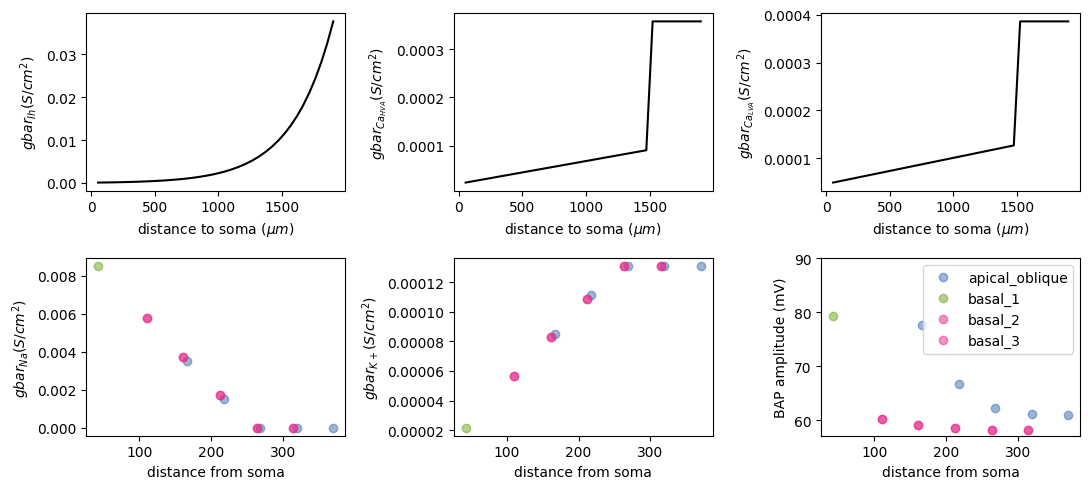

In [173]:
# get paramaters
section_params, end_pts, cell_tree = l5_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'soma': -64,
            'basal_1': -64,
            'basal_2': -64,
            'basal_3': -64,
            'apical_oblique': -64,
            'apical_trunk': -64,
            'apical_1': -64,
            'apical_2': -60,
            'apical_tuft': -58}

sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=v_init['soma'])

mech_class = Mechs(pth_mod)


hotzone = [1500, 2000]
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()

l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)


# Show conductances

fig = fig_conductances(l5pyr)

fig.savefig(os.path.join(figpth, 'conductances.png'))


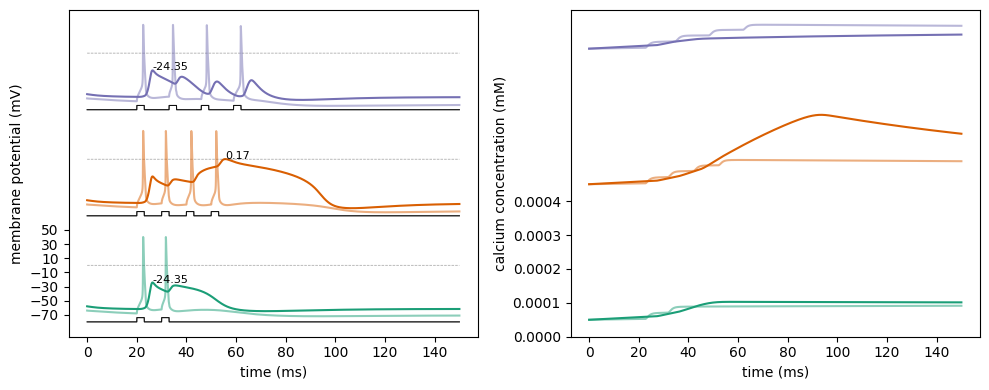

In [174]:
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
fig, ax = plt.subplots(1, 2, figsize=(10,4))
h('forall delete_section()')
nums_pulse = [2, 4, 4]
time_diff = [10, 10, 13]
l_stim = 150

section_names = ['apical_tuft', 'soma']

voltg = [None]*len(section_names)
ca = [None]*len(section_names)

for n, num_pulse in enumerate(nums_pulse):
    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()

    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

    stim = [None]*num_pulse
    t = h.Vector().record(h._ref_t)
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
        stim[i].delay = 20+(time_diff[n]*i)
        stim[i].dur = 3
        stim[i].amp = 3


    for s, section in enumerate(section_names):
        voltg[s] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)
        ca[s] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_cai)


    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    clamp_current = np.zeros_like(t.as_numpy())
    for i in range(num_pulse):
        clamp_current[(t.as_numpy() > stim[i].delay) & (t.as_numpy() < stim[i].delay+stim[i].dur)] = stim[i].amp

    for s, section in enumerate(section_names):
        ax[0].plot(t.as_numpy(), np.zeros_like(t.as_numpy())+n*150, color='black', alpha=0.2, linewidth=0.5, linestyle='--')
        ax[0].plot(t, voltg[s]+n*150, color=cols[n], alpha=1/(s+1))
        ax[0].plot(t.as_numpy(), clamp_current*2+n*150-80, color='black', alpha=0.75, linewidth=0.75)


        if section == 'apical_tuft':
            v_max = np.max(voltg[s].as_numpy())
            t_max = np.argmax(voltg[s].as_numpy())
            ax[0].text(t[t_max], v_max+n*150, f'{v_max:.2f}', fontsize=8)
            
            ax[1].plot(t, ca[s]+n*0.0004, label=f'{num_pulse} pulses, {time_diff[n]} ms apart', color=cols[n], alpha=1/(s+1))
            
        else:
            ax[1].plot(t, ca[s]+n*0.0004, color=cols[n], alpha=1/(s+1))
        
        


ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_xlabel('time (ms)')
ax[0].set_yticks(np.arange(-70, 70, 20))
ax[1].set_ylabel('calcium concentration (mM)')
ax[1].set_xlabel('time (ms)')
ax[1].set_yticks(np.arange(0, 0.0005, 0.0001))



fig.tight_layout()
fig.savefig(figpth+'soma_vs_apical_critfreq.png')
fig.savefig(figpth+f'soma_vs_apical_critfreq.svg', format='svg')

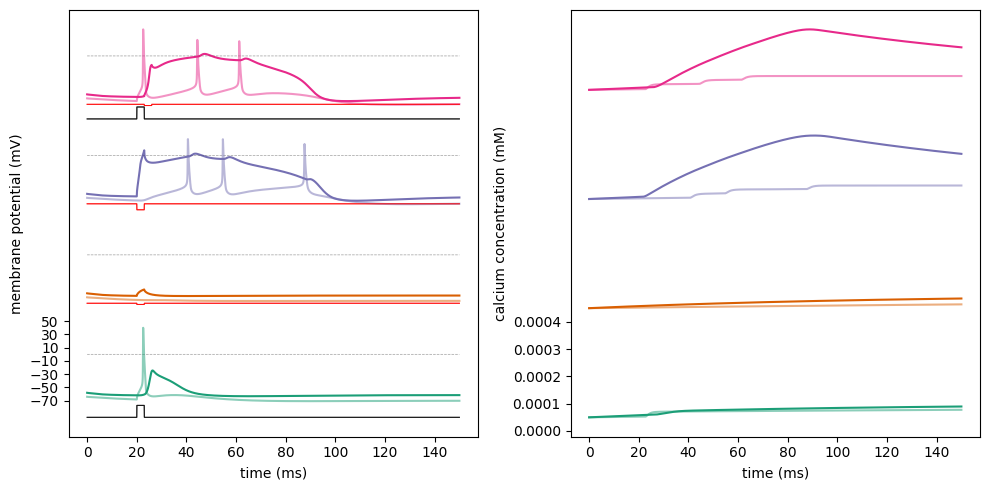

In [171]:
fig, ax = plt.subplots(1, 2, figsize=(10,5))

h('forall delete_section()')
nums_pulse = [1, 1, 1, 2]
pulse_sect = [['soma'], ['apical_tuft'], ['apical_tuft'],['soma', 'apical_tuft']]
ampl = [[3], [0.3], [1.5], [3, 0.3]]
time_diff = [[0], [0], [0], [0, 3]]
l_stim = 150

section_names = ['apical_tuft', 'soma']

voltg = [None]*len(section_names)
ca = [None]*len(section_names)

for n, num_pulse in enumerate(nums_pulse):
    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()

    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

    stim = [None]*num_pulse
    t = h.Vector().record(h._ref_t)
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections[pulse_sect[n][i]](0.5))
        stim[i].delay = 20+(time_diff[n][i])
        stim[i].dur = 3
        stim[i].amp = ampl[n][i]


    for s, section in enumerate(section_names):
        voltg[s] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)
        ca[s] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_cai)


    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    clamp_current = np.zeros((num_pulse, len(t.as_numpy())))
    for i in range(num_pulse):
        clamp_current[i][(t.as_numpy() > stim[i].delay) & (t.as_numpy() < stim[i].delay+stim[i].dur)] = stim[i].amp*3

    for s, section in enumerate(section_names):
        ax[0].plot(t.as_numpy(), np.zeros_like(t.as_numpy())+n*150, color='black', alpha=0.2, linewidth=0.5, linestyle='--')
        ax[0].plot(t, voltg[s]+n*150, color=cols[n], alpha=1/(s+1))
        for i in range(num_pulse):
            if pulse_sect[n][i] == 'soma':
                col = 'black'
                c = clamp_current[i]*2+n*150-95
            else:
                col = 'red'
                c = -clamp_current[i]*2+n*150-73
            ax[0].plot(t.as_numpy(), c, color=col, alpha=0.75, linewidth=0.75)


        if section == 'apical_tuft':
            v_max = np.max(voltg[s].as_numpy())
            t_max = np.argmax(voltg[s].as_numpy())
            
            ax[1].plot(t, ca[s]+n*0.0004, label=f'{num_pulse} pulses, {time_diff[n]} ms apart', color=cols[n], alpha=1/(s+1))
            
        else:
            ax[1].plot(t, ca[s]+n*0.0004, color=cols[n], alpha=1/(s+1))
        
        


ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_xlabel('time (ms)')
ax[0].set_yticks(np.arange(-70, 70, 20))
ax[1].set_ylabel('calcium concentration (mM)')
ax[1].set_xlabel('time (ms)')
ax[1].set_yticks(np.arange(0, 0.0005, 0.0001))



fig.tight_layout()
fig.savefig(figpth+'soma_vs_apical_coincidence.png')
fig.savefig(figpth+f'soma_vs_apical_coincidence.svg', format='svg')

# add basal dendrites

HNN cell_default: proximal drive is basal_2, basal_3 and apical_oblique https://github.com/jonescompneurolab/hnn-core/blob/master/hnn_core/cells_default.py#L115

In [6]:
def epsp_sim(sections, cell_tree, epsp_strength = 1):

    # check EPSP effect
    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

    syn_inp = h.epsp(l5pyr._nrn_sections['basal_2'](0.9))
    syn_inp.onset = 5
    syn_inp.imax = epsp_strength

    h.distance(sec = l5pyr._nrn_sections['soma'])
    segments = [seg.x for seg in l5pyr._nrn_sections['basal_2']]

    voltg_basal = [None]*len(segments)
    for i, seg in enumerate(l5pyr._nrn_sections['basal_2']):
        voltg_basal[i] = h.Vector().record(seg._ref_v)

    voltg_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    l_stim = 100
    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    return segments, voltg_basal, voltg_soma, t

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_3945/674115756.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


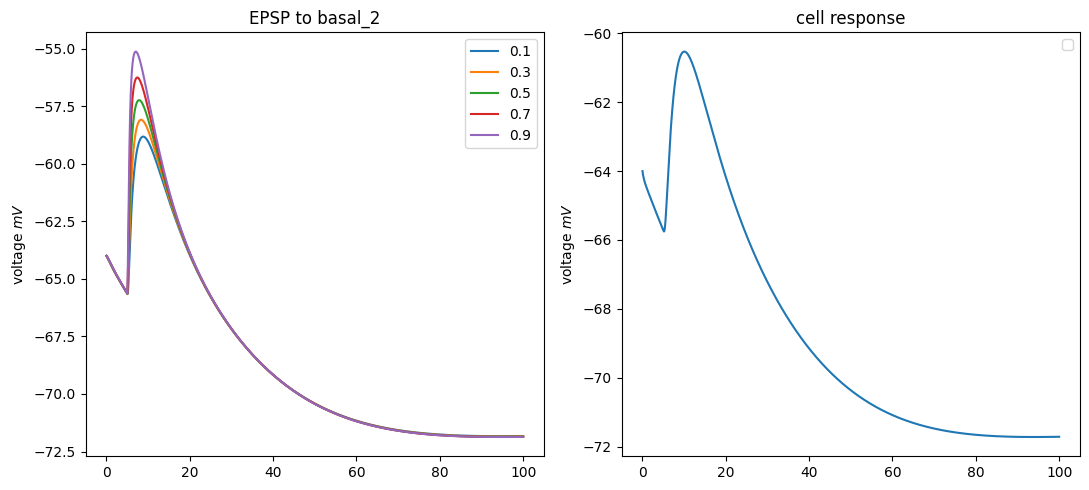

In [7]:
fig, ax = plt.subplots(1,2,figsize=(11,5))

segments, voltg_basal, voltg_soma, t = epsp_sim(sections, cell_tree,1)

for i,v in enumerate(voltg_basal):
    ax[0].plot(t,v, label=str(segments[i]))

ax[0].set_title(f'EPSP to basal_2')
ax[0].set_ylabel('voltage $m V$')

ax[1].plot(t,voltg_soma)

ax[1].set_title('cell response')
ax[1].set_ylabel('voltage $m V$')

ax[0].legend()
ax[1].legend()
fig.tight_layout()
fig.savefig(figpth+'basal_dendrites_epsps.png')

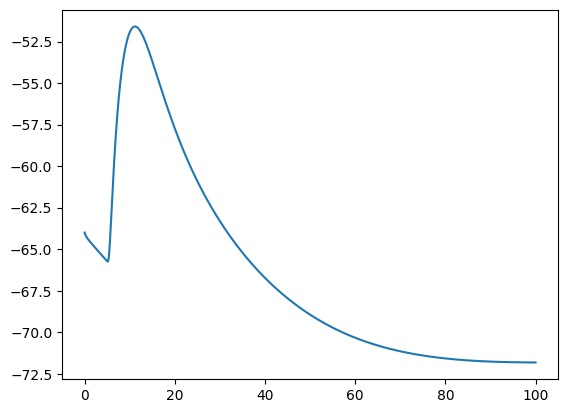

In [8]:
# check EPSP effect
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

syn_inp1 = h.epsp(l5pyr._nrn_sections['basal_2'](0.9))
syn_inp1.onset = 5
syn_inp1.imax = 1.1

syn_inp2 = h.epsp(l5pyr._nrn_sections['basal_3'](0.9))
syn_inp2.onset = 5
syn_inp2.imax = 1.1


voltg_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

t = h.Vector().record(h._ref_t)

l_stim = 100
h.celsius = 37
h.finitialize()
h.continuerun(l_stim * ms)

plt.plot(t, voltg_soma)

In [9]:
# Compare Ih Rich et al., 2021 vs Hay et al., 2011